# PARTE 2: Algoritmo Árvores de Decisão

Nesta segunda parte do Trabalho você irá aplicar os algoritmos de Árvore de Decisão e de Floresta Aleatória na base de dados de risco de crédito discutida em aula. Para isso você deve primeiramente importar as bibliotecas necessárias.

In [154]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px

# 1 - Importação dos dados Pré-Processados

a) importe o arquivo salvo como 'risco_credito.pkl'



In [155]:
import pickle
with open('risco_credito.pkl', 'rb') as f:
  X_risco_credito, y_risco_credito = pickle.load(f)

# 2 - Algoritmo de Árvore de Decisão



a) importar da biblioteca sklearn o pacote DecisionTreeClassifier

b) Calcule a árvore de decisão, utilizando como critério a entropia.
Coloque como nome da variável: arvore_risco_credito

c) Utilize o feature_importances_ para retornar a importância de cada atributo. Qual possui o maior ganho de informação?

d) Gere uma visualização da sua árvore de decisão utilizando o pacote tree da biblioteca do sklearn.

OBS: Adicione cores, nomes para os atributos e para as classes.

e) FAZER A PREVISÃO

Utilize .predict para fazer a previsão realizada no exemplo em sala.

   i. história boa, dívida alta, garantia nenhuma, renda > 35

   ii. história ruim, dívida alta, garantia adequada, renda < 15


Verifique nos slides se seu resultado está correto!

(14, 4)
(14,)

Feature mais importante tem peso (renda): 0.4831428973434128

Previsões: ['baixo' 'alto']

[Text(0.5, 0.9, 'renda <= 1.5\nentropy = 1.531\nsamples = 14\nvalue = [6, 5, 3]\nclass = alto'), Text(0.2, 0.7, 'renda <= 0.5\nentropy = 0.863\nsamples = 7\nvalue = [5, 0, 2]\nclass = alto'), Text(0.35, 0.8, 'True  '), Text(0.1, 0.5, 'entropy = 0.0\nsamples = 3\nvalue = [3, 0, 0]\nclass = alto'), Text(0.3, 0.5, 'historia <= 0.5\nentropy = 1.0\nsamples = 4\nvalue = [2, 0, 2]\nclass = alto'), Text(0.2, 0.3, 'entropy = 0.0\nsamples = 1\nvalue = [0, 0, 1]\nclass = baixo'), Text(0.4, 0.3, 'divida <= 0.5\nentropy = 0.918\nsamples = 3\nvalue = [2, 0, 1]\nclass = alto'), Text(0.3, 0.1, 'entropy = 0.0\nsamples = 2\nvalue = [2, 0, 0]\nclass = alto'), Text(0.5, 0.1, 'entropy = 0.0\nsamples = 1\nvalue = [0, 0, 1]\nclass = baixo'), Text(0.8, 0.7, 'historia <= 1.5\nentropy = 1.149\nsamples = 7\nvalue = [1, 5, 1]\nclass = moderado'), Text(0.65, 0.8, '  False'), Text(0.7, 0.5, 'historia <= 0.5\nen

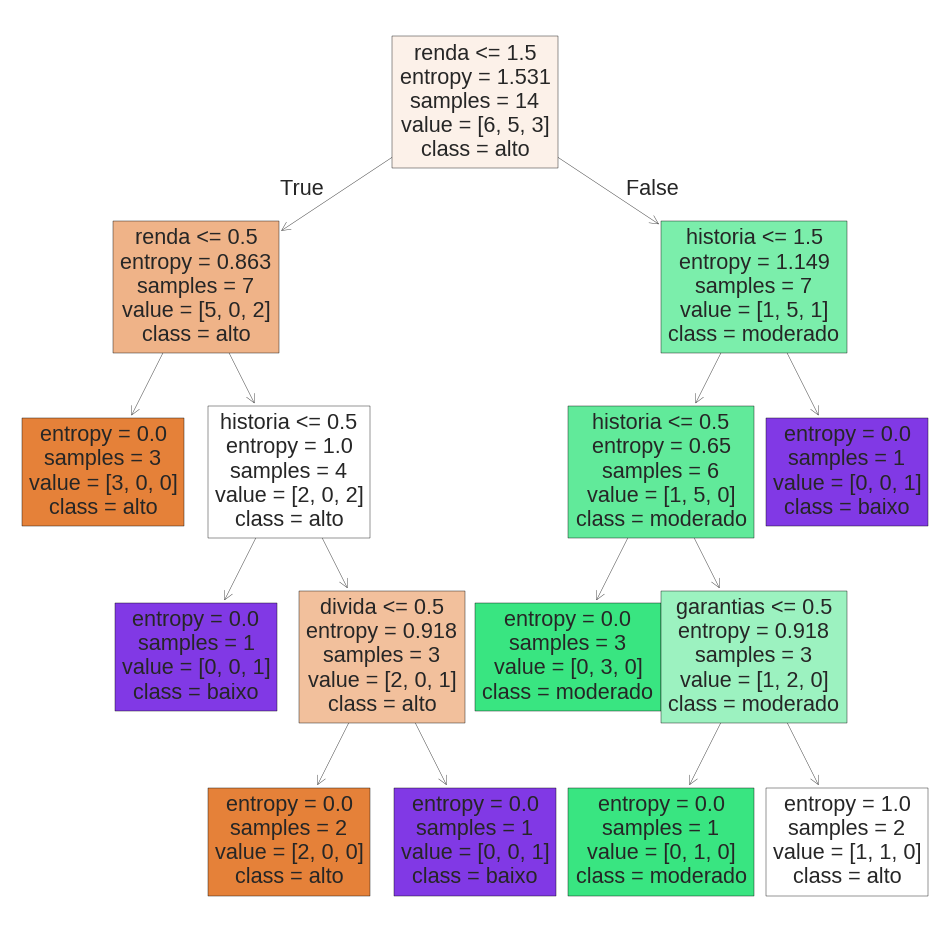

In [156]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

print(X_risco_credito.shape)
print(y_risco_credito.shape)

arvore_credit = DecisionTreeClassifier(criterion='entropy', random_state=0)
arvore_credit.fit(X_risco_credito, y_risco_credito)

importances = arvore_credit.feature_importances_

print()
print(f"Feature mais importante tem peso (renda): {max(importances)}")


print()
print(f'Previsões: {arvore_credit.predict([[0,0,1,2],[2,0,0,0]])}')

fig, ax = plt.subplots(figsize=(12,12))

print()
print(
    plot_tree(
        arvore_credit,
        feature_names=['historia', 'divida', 'garantias', 'renda'],  # X
        class_names=['alto', 'moderado', 'baixo'],  # y
        filled=True,
        ax=ax
    )
)

#3 - Algoritmo de Árvore de Decisão para uma base de dados maior (Credit Data)

Nesta seção você deverá testar o uso da Árvore de Decisão para a Base de Dados Credit Risk Dataset. Aqui estaremos analisando os clientes que pagam (classe 0) ou não pagam a dívida (classe 1), a fim do banco conceder empréstimo.

In [157]:
# abrir o arquivo
with open('credit.pkl', 'rb') as f:
  X_credit_treinamento, y_credit_treinamento, X_credit_teste, y_credit_teste = pickle.load(f)

a) Ao abrir o arquivo utilize .shape para verificar o tamanho dos dados de

---

treinamento e de teste

OBS: os dados de treinamento devem ter as seguintes dimenções: x=(1500, 3), y=(1500,); os dados de teste devem ter as seguintes dimenções: x=(500, 3), y=(500,)

b) Importe o pacote DecisionTreeClassifier do sklearn para treinar o seu algoritmo de árvore de decisão. Para poder refazer os testes e obter o mesmo resultado utilize o parâmetro random_state = 0.

c) Faça a previsão com os dados de teste. Visualize os dados e verifique se as previsões estão de acordo com os dados de teste (respostas reais).

In [158]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

print("Shapes:")
print(X_credit_treinamento.shape)
print(y_credit_treinamento.shape)
print(X_credit_teste.shape)
print(y_credit_teste.shape)

arvore_credit = DecisionTreeClassifier(criterion='entropy', random_state=0)
arvore_credit.fit(X_credit_treinamento, y_credit_treinamento)

y_chapeu = arvore_credit.predict(X_credit_teste)

print()
print(y_chapeu)
print(y_credit_teste)

print()
print(f'Todos estão corretos?: {'Sim' if np.array_equal(y_chapeu, y_credit_teste) else 'Não'}')

Shapes:
(1500, 3)
(1500,)
(500, 3)
(500,)

[1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1
 0 0 0 0 0 0 0 0 1 1 0 1 0 0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 0 0 0 0 1 0 0 1 0
 0 1 0 0 1 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 1 0 0 0 0
 0 1 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0
 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 1 0
 0 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 0 0 0 0 0 0 0 0 0 0 1 0
 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 1 1 0 0 0 0 0 0 0 0 1 0 1
 0 1 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0
 1 0 0 0 0 0 0 0 1 0 0 0 0 0 1 1 0 0 0 1 0 0 0 0 0 1 0 0 0 0 0 1 0 0 0 0 0
 0 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0 1 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0
 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 1 0 0
 1 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 

d) Agora faça o cálculo da acurácia para calcular a taxa de acerto entre os valores reais (y teste) e as previsões

In [159]:
from sklearn.metrics import accuracy_score, classification_report

print()
print(f'Acurácia: {accuracy_score(y_credit_teste, y_chapeu):.3f}')


Acurácia: 0.982


e) Faça a análise da Matriz de Confusão.

i. Quantos clientes foram classificados corretamente que pagam a dívida?

ii. Quantos clientes foram classificados incorretamente como não pagantes?

iii. Quantos clientes foram classificados corretamente que não pagam?

iv. Quantos clientes foram classificados incorretamente como pagantes?

0.982

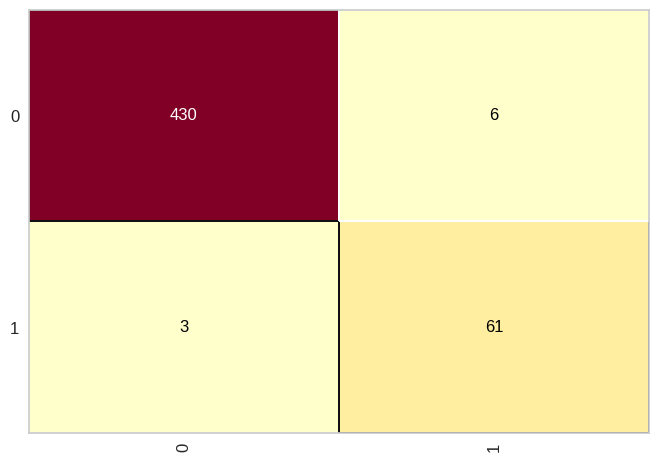

In [160]:
from yellowbrick.classifier import ConfusionMatrix
cm = ConfusionMatrix(arvore_credit)
cm.fit(X_credit_treinamento, y_credit_treinamento)
cm.score(X_credit_teste, y_credit_teste)

# TODO

f) Faça um print do parâmetro classification_report entre os dados de teste e as previsões. Explique qual é a relação entre precision e recall nos dados. Como você interpreta esses dados?

In [161]:
from sklearn.metrics import classification_report

print(classification_report(y_credit_teste, y_chapeu))

print()
print('As métricas de precision e recall avaliam a proporção entre falsos-negativos e falsos-positivos nos dados.')
print('Como ambos precision e recall foram altos, significa que a taxa de falsos-negativos e falsos-positivos é baixa o \nsuficiente para não interferir na acurácia, que é alta.')

# TODO: Analisar com base nas classes do problema

              precision    recall  f1-score   support

           0       0.99      0.99      0.99       436
           1       0.91      0.95      0.93        64

    accuracy                           0.98       500
   macro avg       0.95      0.97      0.96       500
weighted avg       0.98      0.98      0.98       500


As métricas de precision e recall avaliam a proporção entre falsos-negativos e falsos-positivos nos dados.
Como ambos precision e recall foram altos, significa que a taxa de falsos-negativos e falsos-positivos é baixa o 
suficiente para não interferir na acurácia, que é alta.


g) Gere uma visualização da sua árvore de decisão utilizando o pacote tree da biblioteca do sklearn.

OBS 1: Os atributos previsores são = ['income', 'age', 'loan']

OBS 2: Adicione cores, nomes para os atributos e para as classes. Você pode utilizar a função fig.savefig para salvar a árvore em uma imagem .png

[Text(0.47619047619047616, 0.9444444444444444, 'age <= -0.453\nentropy = 0.6\nsamples = 1500\nvalue = [1281, 219]\nclass = 0'), Text(0.42857142857142855, 0.8333333333333334, 'loan <= -0.253\nentropy = 0.963\nsamples = 565\nvalue = [346, 219]\nclass = 0'), Text(0.45238095238095233, 0.8888888888888888, 'True  '), Text(0.14285714285714285, 0.7222222222222222, 'income <= -1.241\nentropy = 0.284\nsamples = 263\nvalue = [250, 13]\nclass = 0'), Text(0.09523809523809523, 0.6111111111111112, 'loan <= -0.644\nentropy = 0.722\nsamples = 65\nvalue = [52, 13]\nclass = 0'), Text(0.047619047619047616, 0.5, 'entropy = 0.0\nsamples = 46\nvalue = [46, 0]\nclass = 0'), Text(0.14285714285714285, 0.5, 'income <= -1.64\nentropy = 0.9\nsamples = 19\nvalue = [6, 13]\nclass = 1'), Text(0.09523809523809523, 0.3888888888888889, 'entropy = 0.0\nsamples = 8\nvalue = [0, 8]\nclass = 1'), Text(0.19047619047619047, 0.3888888888888889, 'loan <= -0.487\nentropy = 0.994\nsamples = 11\nvalue = [6, 5]\nclass = 0'), Text(0

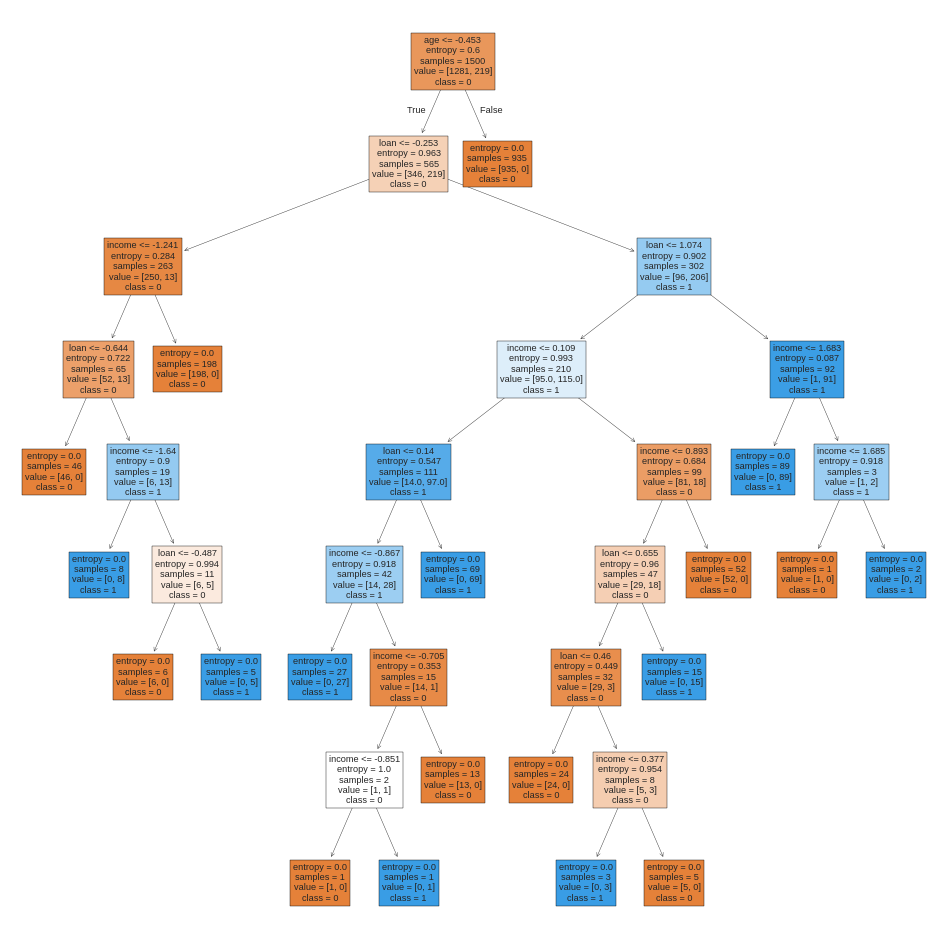

In [162]:
from sklearn.tree import plot_tree

fig, ax = plt.subplots(figsize=(12,12))

print(
    plot_tree(
        arvore_credit,
        feature_names=['income', 'age', 'loan'],  # X
        class_names=['0', '1'],  # y
        filled=True,
        ax=ax
    )
)

# Algoritmo Random Forest

Nesta seção iremos utilizar o algoritmo Random Forest para a mesma base de crédito (**Credit Risk Dataset**) - arquivo *credit.pkl*.

a) Importe o pacote RandomForestClassifier do sklearn para treinar o seu algoritmo de floresta randomica.

In [163]:
from sklearn.ensemble import RandomForestClassifier

b) Para gerar a classificação você deve adicionar alguns parâmetros:
*   n_estimators=10  --> número de árvores que você irá criar
*   criterion='entropy'
*   random_state = 0

In [164]:
floresta = RandomForestClassifier(n_estimators=10, criterion='entropy', random_state=0)
floresta.fit(X_credit_treinamento, y_credit_treinamento)

RandomForestClassifier(criterion='entropy', n_estimators=10, random_state=0)

c) Faça a previsão com os dados de teste. Visualize os dados e verifique se as previsões estão de acordo com os dados de teste (respostas reais).

In [165]:
y_chapeu_floresta = floresta.predict(X_credit_teste)

print()
print(f'Todos estão corretos?: {'Sim' if np.array_equal(y_chapeu_floresta, y_credit_teste) else 'Não'}')


Todos estão corretos?: Não


d) Agora faça o cálculo da acurácia para calcular a taxa de acerto entre os valores reais (y teste) e as previsões. O resultado foi melhor do que a árvore de decisão simples?

In [166]:
from sklearn.metrics import accuracy_score, classification_report

print()
print(f'Acurácia: {accuracy_score(y_credit_teste, y_chapeu_floresta):.3f}')

print()
print('Em valor absoluto, a acurácia acusou ser pior na floresta randômica ao comparar com a árvore de decisão.')


Acurácia: 0.968

Em valor absoluto, a acurácia acusou ser pior na floresta randômica ao comparar com a árvore de decisão.


e) Se o resultado foi inferior, como você poderia resolver isso? Quais foram os resultados obtidos?

In [167]:
print(f'Os resultados obtidos para acurácia foram {.982} e {.968}, respectivamente para árvore de decisão e floresta randômica.')

n_estimators = 100  # TODO: entre 10 e 100, 10 em 10
random_state = 0  # seed de randomicidade do modelo, manter em 0 para assegurar treinamento sem viés

floresta_maior = RandomForestClassifier(n_estimators=n_estimators, criterion='entropy', random_state=random_state)
floresta_maior.fit(X_credit_treinamento, y_credit_treinamento)

y_chapeu_floresta_maior = floresta_maior.predict(X_credit_teste)

print()
print(f'Acurácia (n_estimators={n_estimators}, random_state={random_state}): {accuracy_score(y_credit_teste, y_chapeu_floresta_maior):.3f}')

print()
print(f'Ao aumentar o número de árvores presentes na floresta (n_estimators) obtemos resultados melhores, igualando a acurácia à da etapa anterior.')

print(f'Em outra tentativa, tentamos ajustar a randomicidade do modelo (random_state), mas isso iria enviesar o modelo, \nnão sendo recomendado para ajuste neste caso.')

# TODO: Analisar com base nas classes do problema

Os resultados obtidos para acurácia foram 0.982 e 0.968, respectivamente para árvore de decisão e floresta randômica.

Acurácia (n_estimators=100, random_state=0): 0.982

Ao aumentar o número de árvores presentes na floresta (n_estimators) obtemos resultados melhores, igualando a acurácia à da etapa anterior.
Em outra tentativa, tentamos ajustar a randomicidade do modelo (random_state), mas isso iria enviesar o modelo, 
não sendo recomendado para ajuste neste caso.


ff) Faça a análise da Matriz de Confusão.

0.968

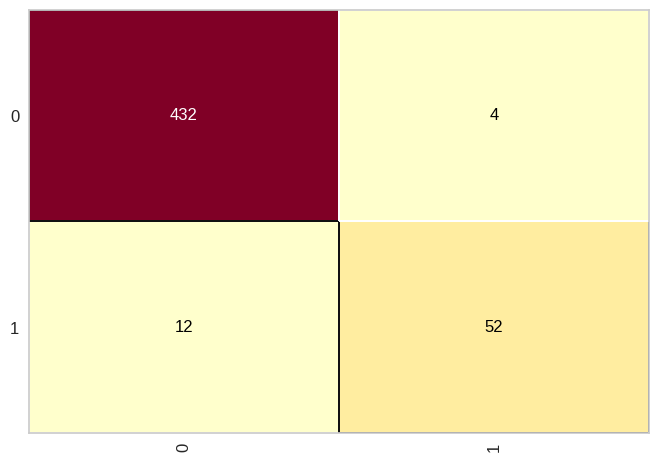

In [168]:
from yellowbrick.classifier import ConfusionMatrix
cm = ConfusionMatrix(floresta)
cm.fit(X_credit_treinamento, y_credit_treinamento)
cm.score(X_credit_teste, y_credit_teste)

g) Faça um print do parâmetro classification_report entre os dados de teste e as previsões. Explique qual é a relação entre precision e recall nos dados. Como você interpreta esses dados?

In [169]:
from sklearn.metrics import classification_report

print(classification_report(y_credit_teste, y_chapeu_floresta))

print()
print('A quantidade de falsos-negativos aumentou, puxando o recall para baixo. Já a quantidade de falsos-positivos diminuiu ligeiramente, mantando a precisão alta.')
print('Isso impactou na ligeira diminuição da acurácia, mas ainda próxima entre modelos. Além disso, o score total teve diferença significativa, \nmostrando que embora a acurácia seja próxima entre os modelos, o score sofreu com o recall mais baixo.')

# TODO: Analisar com base nas classes do problema

              precision    recall  f1-score   support

           0       0.97      0.99      0.98       436
           1       0.93      0.81      0.87        64

    accuracy                           0.97       500
   macro avg       0.95      0.90      0.92       500
weighted avg       0.97      0.97      0.97       500


A quantidade de falsos-negativos aumentou, puxando o recall para baixo. Já a quantidade de falsos-positivos diminuiu ligeiramente, mantando a precisão alta.
Isso impactou na ligeira diminuição da acurácia, mas ainda próxima entre modelos. Além disso, o score total teve diferença significativa, 
mostrando que embora a acurácia seja próxima entre os modelos, o score sofreu com o recall mais baixo.
